Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 165888)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    21,233,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 21,309,569 (81.29 MB)

Trainable params: 21,309,569 (81.29 MB)

Non-trainable params: 0 (0.00 B)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.5791 - loss: 1.4706 - val_accuracy: 0.6907 - val_loss: 0.5794 - learning_rate: 0.0010
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.7094 - loss: 0.5552 - val_accuracy: 0.6490 - val_loss: 0.6028 - learning_rate: 0.0010
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.8020 - loss: 0.4467 - val_accuracy: 0.7761 - val_loss: 0.4896 - learning_rate: 0.0010
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 111s 2s/step - accuracy: 0.7726 - loss: 0.4574 - val_accuracy: 0.7306 - val_loss: 0.5419 - learning_rate: 0.0010
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 116s 2s/step - accuracy: 0.8030 - loss: 0.4157 - val_accuracy: 0.7457 - val_loss: 0.4945 - learning_rate: 0.0010
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7933 - loss: 0.4025
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.
66/66 ━━━━━━━━━━━━━━━━━━━━ 116s 2s/step - accuracy: 0.7933 - loss: 0.4026 - val_accur

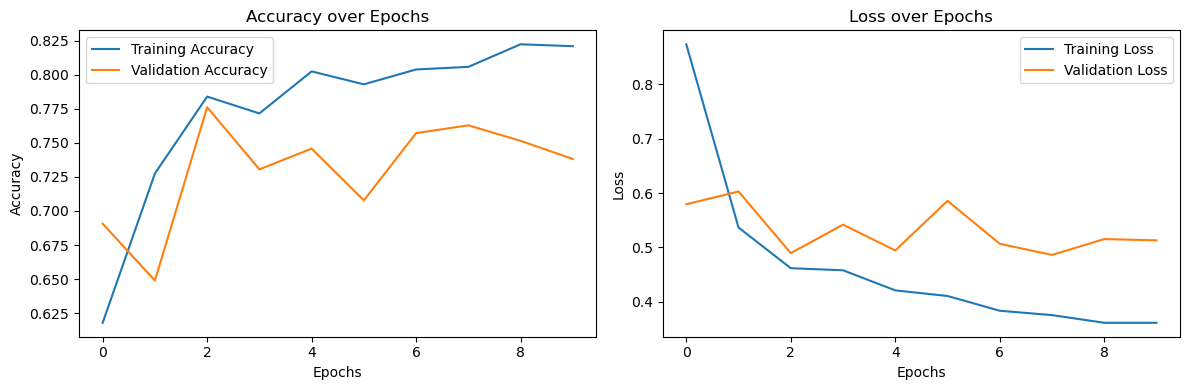

In [24]:
import zipfile
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.callbacks import ReduceLROnPlateau

# Step 1: Extract the dataset (if necessary)
# Step 1: Define the path for your extracted dataset (since you already extracted it)
extract_path = 'dataset Skin'  # Path to the extracted folder
train_dir = os.path.join(extract_path, 'train')
val_dir = os.path.join(extract_path, 'val')
test_dir = os.path.join(extract_path, 'test')

# Create extraction directory if it doesn't exist
if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

# Step 2: Define paths for train, validation, and test sets
train_dir = os.path.join(extract_path, 'train')
val_dir = os.path.join(extract_path, 'val')
test_dir = os.path.join(extract_path, 'test')

# Step 3: Load and preprocess the data
img_size = 150  # Resize images to 150x150

def load_images(data_dir, img_size):
    data = []
    labels = []
    categories = ['BENIGN', 'MALIGNANT']  # Adjust according to your dataset labels
    
    for category in categories:
        path = os.path.join(data_dir, category)
        class_label = categories.index(category)
        for img in os.listdir(path):
            try:
                img_array = cv2.imread(os.path.join(path, img))
                resized_img = cv2.resize(img_array, (img_size, img_size))
                data.append(resized_img)
                labels.append(class_label)
            except Exception as e:
                print(f"Error loading image: {e}")
    
    return np.array(data), np.array(labels)

train_data, train_labels = load_images(train_dir, img_size)
val_data, val_labels = load_images(val_dir, img_size)
test_data, test_labels = load_images(test_dir, img_size)

# Step 4: Normalize the data
X_train = train_data / 255.0
X_val = val_data / 255.0
X_test = test_data / 255.0

# Reshape data to fit the model input requirements (150, 150, 3)
X_train = X_train.reshape(-1, img_size, img_size, 3)
X_val = X_val.reshape(-1, img_size, img_size, 3)
X_test = X_test.reshape(-1, img_size, img_size, 3)

# Convert labels to NumPy arrays
y_train = np.array(train_labels)
y_val = np.array(val_labels)
y_test = np.array(test_labels)

# Step 5: Data Augmentation
data_generator = ImageDataGenerator(
    rotation_range=30,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

data_generator.fit(X_train)

# Step 6: Build the CNN model
model = Sequential([
    Conv2D(64, kernel_size=(3, 3), activation='relu', input_shape=(img_size, img_size, 3)),
    MaxPool2D(pool_size=(2, 2)),
    
    Conv2D(128, kernel_size=(3, 3), activation='relu'),
    MaxPool2D(pool_size=(2, 2)),
    
    Flatten(),
    
    Dense(128, activation='relu'),
    Dropout(0.5),
    
    Dense(1, activation='sigmoid')  # Binary classification (Normal vs Malignant)
])

# Compile the model
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# Step 7: Train the model
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, verbose=1, min_lr=0.00001)

history = model.fit(
    data_generator.flow(X_train, y_train, batch_size=32),
    epochs=10,
    validation_data=(X_val, y_val),
    callbacks=[reduce_lr]
)

# Step 8: Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Step 9: Confusion Matrix and Classification Report
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype(int)

print("Classification Report:\n", classification_report(y_test, y_pred_classes))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_classes))

# Step 10: Visualize training results
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 148, 148, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 74, 74, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 72, 72, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 36, 36, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 165888)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │    21,233,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 21,309,569 (81.29 MB)

Trainable params: 21,309,569 (81.29 MB)

Non-trainable params: 0 (0.00 B)

Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


66/66 ━━━━━━━━━━━━━━━━━━━━ 117s 2s/step - accuracy: 0.6366 - loss: 1.0439 - val_accuracy: 0.6603 - val_loss: 0.5682 - learning_rate: 0.0010
Epoch 2/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.7394 - loss: 0.5103 - val_accuracy: 0.6110 - val_loss: 0.6930 - learning_rate: 0.0010
Epoch 3/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.7538 - loss: 0.4794 - val_accuracy: 0.7704 - val_loss: 0.4971 - learning_rate: 0.0010
Epoch 4/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.8012 - loss: 0.4071 - val_accuracy: 0.7704 - val_loss: 0.5124 - learning_rate: 0.0010
Epoch 5/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.7818 - loss: 0.4243 - val_accuracy: 0.7552 - val_loss: 0.5651 - learning_rate: 0.0010
Epoch 6/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.7882 - loss: 0.4602 - val_accuracy: 0.7704 - val_loss: 0.4752 - learning_rate: 0.0010
Epoch 7/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.8140 - loss: 0.3849 - val_accuracy: 0.78

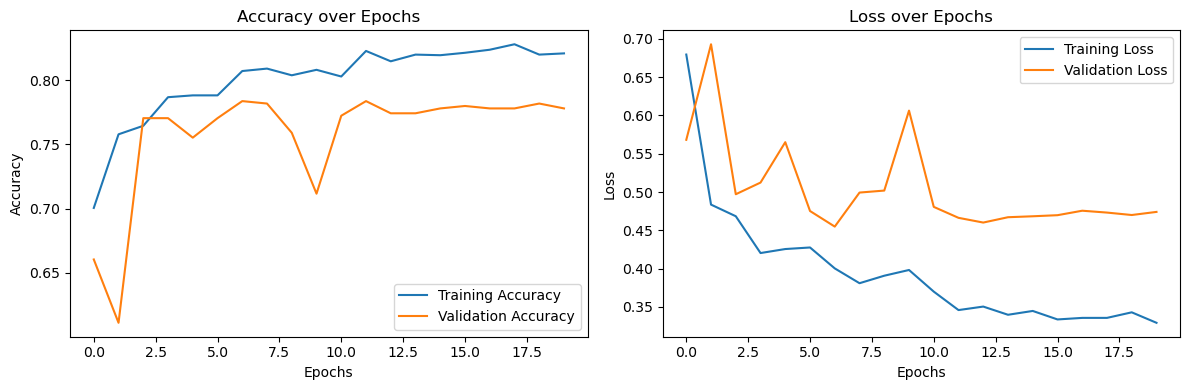

In [25]:
import zipfile
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.callbacks import ReduceLROnPlateau

# Step 1: Define the path for your extracted dataset
extract_path = 'dataset Skin'  # Path to the extracted folder
train_dir = os.path.join(extract_path, 'train')
val_dir = os.path.join(extract_path, 'val')
test_dir = os.path.join(extract_path, 'test')

# Step 2: Load and preprocess the data
img_size = 150  # Resize images to 150x150

def load_images(data_dir, img_size):
    data = []
    labels = []
    categories = ['BENIGN', 'MALIGNANT']  # Adjust according to your dataset labels
    
    for category in categories:
        path = os.path.join(data_dir, category)
        class_label = categories.index(category)
        for img in os.listdir(path):
            try:
                img_array = cv2.imread(os.path.join(path, img))
                resized_img = cv2.resize(img_array, (img_size, img_size))
                data.append(resized_img)
                labels.append(class_label)
            except Exception as e:
                print(f"Error loading image: {e}")
    
    return np.array(data), np.array(labels)

train_data, train_labels = load_images(train_dir, img_size)
val_data, val_labels = load_images(val_dir, img_size)
test_data, test_labels = load_images(test_dir, img_size)

# Step 3: Normalize the data
X_train = train_data / 255.0
X_val = val_data / 255.0
X_test = test_data / 255.0

# Reshape data to fit the model input requirements (150, 150, 3)
X_train = X_train.reshape(-1, img_size, img_size, 3)
X_val = X_val.reshape(-1, img_size, img_size, 3)
X_test = X_test.reshape(-1, img_size, img_size, 3)

# Convert labels to NumPy arrays
y_train = np.array(train_labels)
y_val = np.array(val_labels)
y_test = np.array(test_labels)

# Step 4: Data Augmentation
data_generator = ImageDataGenerator(
    rotation_range=30,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

data_generator.fit(X_train)

# Step 5: Build the CNN model
model = Sequential([
    Conv2D(64, kernel_size=(3, 3), activation='relu', input_shape=(img_size, img_size, 3)),
    MaxPool2D(pool_size=(2, 2)),
    
    Conv2D(128, kernel_size=(3, 3), activation='relu'),
    MaxPool2D(pool_size=(2, 2)),
    
    Flatten(),
    
    Dense(128, activation='relu'),
    Dropout(0.5),
    
    Dense(1, activation='sigmoid')  # Binary classification (Normal vs Malignant)
])

# Compile the model
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# Step 6: Train the model
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, verbose=1, min_lr=0.00001)

history = model.fit(
    data_generator.flow(X_train, y_train, batch_size=32),
    epochs=20,  # Increased epochs for better training
    validation_data=(X_val, y_val),
    callbacks=[reduce_lr]
)

# Step 7: Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Step 8: Confusion Matrix and Classification Report
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype(int)

print("Classification Report:\n", classification_report(y_test, y_pred_classes))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_classes))

# Step 9: Visualize training results
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 18,910,017 (72.14 MB)

Trainable params: 4,195,329 (16.00 MB)

Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/50


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


66/66 ━━━━━━━━━━━━━━━━━━━━ 291s 4s/step - accuracy: 0.6357 - loss: 0.6517 - val_accuracy: 0.8008 - val_loss: 0.4387 - learning_rate: 1.0000e-04
Epoch 2/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 518s 8s/step - accuracy: 0.7862 - loss: 0.4493 - val_accuracy: 0.8140 - val_loss: 0.4116 - learning_rate: 1.0000e-04
Epoch 3/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 338s 5s/step - accuracy: 0.8080 - loss: 0.4094 - val_accuracy: 0.8254 - val_loss: 0.4048 - learning_rate: 1.0000e-04
Epoch 4/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 313s 5s/step - accuracy: 0.8136 - loss: 0.3987 - val_accuracy: 0.8159 - val_loss: 0.3991 - learning_rate: 1.0000e-04
Epoch 5/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 764s 12s/step - accuracy: 0.8377 - loss: 0.3693 - val_accuracy: 0.8235 - val_loss: 0.3890 - learning_rate: 1.0000e-04
Epoch 6/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 299s 5s/step - accuracy: 0.8385 - loss: 0.3439 - val_accuracy: 0.7913 - val_loss: 0.4165 - learning_rate: 1.0000e-04
Epoch 7/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 296s 4s/step - accuracy: 0.8096 - loss: 0.

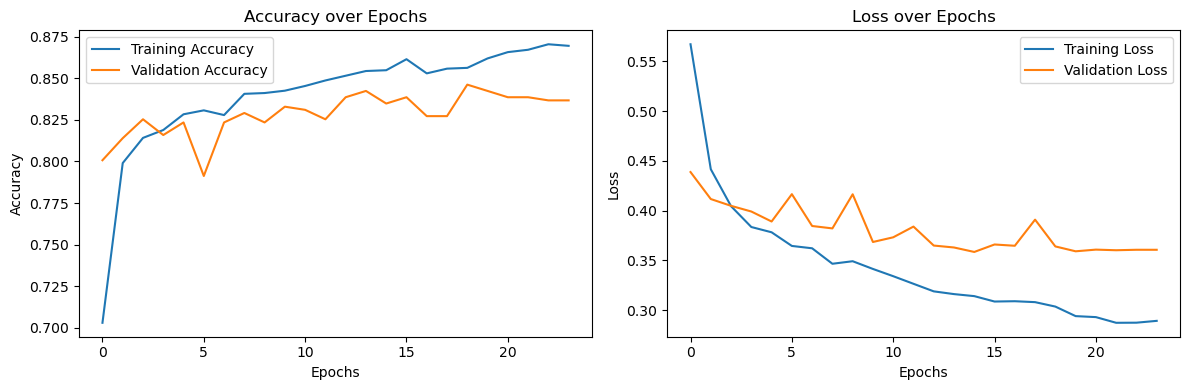

In [35]:
import zipfile
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping

# Step 1: Define the path for your extracted dataset
extract_path = 'dataset Skin'  # Path to the extracted folder
train_dir = os.path.join(extract_path, 'train')
val_dir = os.path.join(extract_path, 'val')
test_dir = os.path.join(extract_path, 'test')

# Step 2: Load and preprocess the data
img_size = 150  # Resize images to 150x150

def load_images(data_dir, img_size):
    data = []
    labels = []
    categories = ['BENIGN', 'MALIGNANT']  # Adjust according to your dataset labels
    
    for category in categories:
        path = os.path.join(data_dir, category)
        class_label = categories.index(category)
        for img in os.listdir(path):
            try:
                img_array = cv2.imread(os.path.join(path, img))
                resized_img = cv2.resize(img_array, (img_size, img_size))
                data.append(resized_img)
                labels.append(class_label)
            except Exception as e:
                print(f"Error loading image: {e}")
    
    return np.array(data), np.array(labels)

train_data, train_labels = load_images(train_dir, img_size)
val_data, val_labels = load_images(val_dir, img_size)
test_data, test_labels = load_images(test_dir, img_size)

# Step 3: Normalize the data
X_train = train_data / 255.0
X_val = val_data / 255.0
X_test = test_data / 255.0

# Reshape data to fit the model input requirements (150, 150, 3)
X_train = X_train.reshape(-1, img_size, img_size, 3)
X_val = X_val.reshape(-1, img_size, img_size, 3)
X_test = X_test.reshape(-1, img_size, img_size, 3)

# Convert labels to NumPy arrays
y_train = np.array(train_labels)
y_val = np.array(val_labels)
y_test = np.array(test_labels)

# Step 4: Data Augmentation
data_generator = ImageDataGenerator(
    rotation_range=30,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

data_generator.fit(X_train)

# Step 5: Use a Pretrained Model for Transfer Learning (VGG16)
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(img_size, img_size, 3))

# Freeze the base model layers so they aren't trained
base_model.trainable = False

# Build the model by adding custom layers on top of the pretrained base model
model = Sequential([
    base_model,
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')  # Binary classification (Normal vs Malignant)
])

# Compile the model
optimizer = Adam(learning_rate=0.0001)  # Use a smaller learning rate for fine-tuning
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# Step 6: Callbacks for better training
checkpoint = ModelCheckpoint('best_model_vgg16.keras', monitor='val_accuracy', save_best_only=True, mode='max')
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, verbose=1, min_lr=1e-6)
early_stopping = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)

# Train the model
history = model.fit(
    data_generator.flow(X_train, y_train, batch_size=32),
    epochs=24,  # You can train for 24 epochs
    validation_data=(X_val, y_val),
    callbacks=[checkpoint, reduce_lr, early_stopping]
)

# Step 7: Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Step 8: Confusion Matrix and Classification Report
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype(int)

print("Classification Report:\n", classification_report(y_test, y_pred_classes))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_classes))

# Step 9: Visualize training results
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 18,910,017 (72.14 MB)

Trainable params: 4,195,329 (16.00 MB)

Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 442s 7s/step - accuracy: 0.6487 - loss: 0.6511 - val_accuracy: 0.7913 - val_loss: 0.4377 - learning_rate: 1.0000e-04
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 437s 7s/step - accuracy: 0.7828 - loss: 0.4747 - val_accuracy: 0.8178 - val_loss: 0.4246 - learning_rate: 1.0000e-04
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 349s 5s/step - accuracy: 0.8054 - loss: 0.4102 - val_accuracy: 0.8083 - val_loss: 0.4017 - learning_rate: 1.0000e-04
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 359s 5s/step - accuracy: 0.8175 - loss: 0.3918 - val_accuracy: 0.8254 - val_loss: 0.3942 - learning_rate: 1.0000e-04
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 335s 5s/step - accuracy: 0.8293 - loss: 0.3771 - val_accuracy: 0.7894 - val_loss: 0.4219 - learning_rate: 1.0000e-04
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 331s 5s/step - accuracy: 0.8131 - loss: 0.3866 - val_accuracy: 0.8216 - val_loss: 0.3884 - learning_rate: 1.0000e-04
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 351s 5s/step - accuracy: 0.8395 

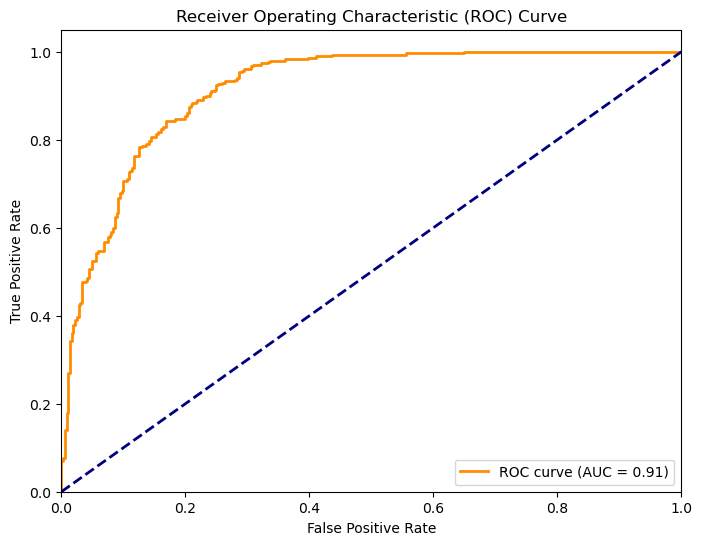

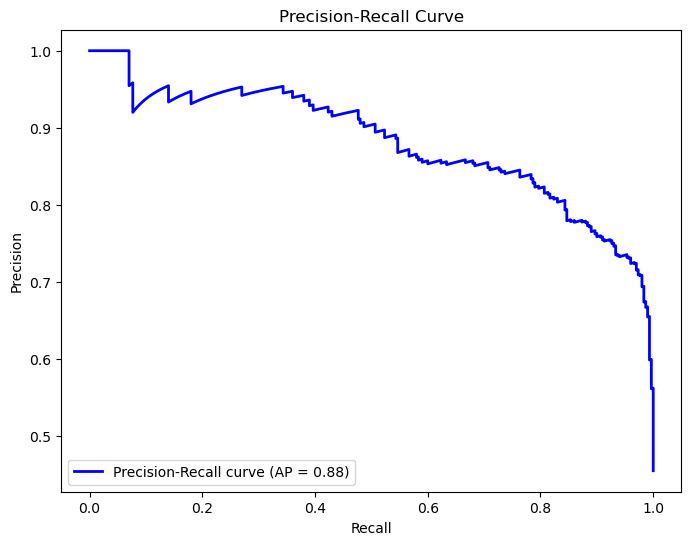

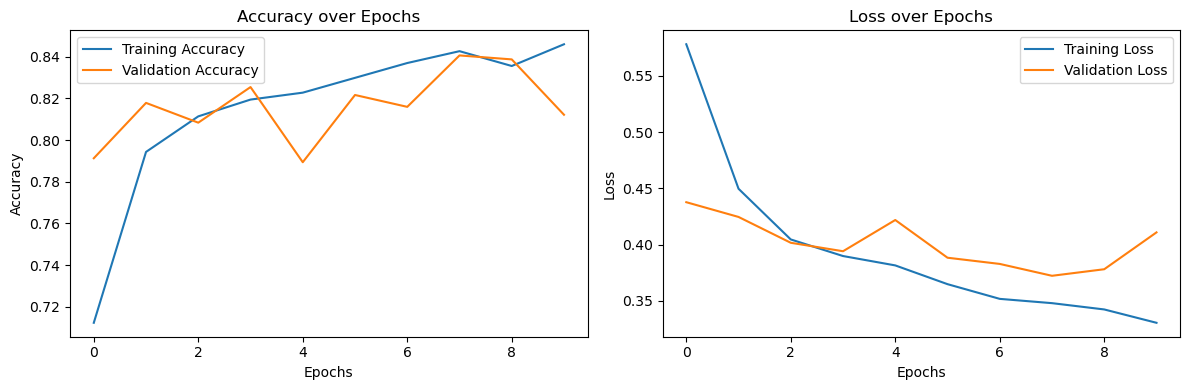

In [42]:
import zipfile
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping

# Step 1: Define the path for your extracted dataset
extract_path = 'dataset Skin'  # Path to the extracted folder
train_dir = os.path.join(extract_path, 'train')
val_dir = os.path.join(extract_path, 'val')
test_dir = os.path.join(extract_path, 'test')

# Step 2: Load and preprocess the data
img_size = 150  # Resize images to 150x150

def load_images(data_dir, img_size):
    data = []
    labels = []
    categories = ['BENIGN', 'MALIGNANT']  # Adjust according to your dataset labels
    
    for category in categories:
        path = os.path.join(data_dir, category)
        class_label = categories.index(category)
        for img in os.listdir(path):
            try:
                img_array = cv2.imread(os.path.join(path, img))
                resized_img = cv2.resize(img_array, (img_size, img_size))
                data.append(resized_img)
                labels.append(class_label)
            except Exception as e:
                print(f"Error loading image: {e}")
    
    return np.array(data), np.array(labels)

train_data, train_labels = load_images(train_dir, img_size)
val_data, val_labels = load_images(val_dir, img_size)
test_data, test_labels = load_images(test_dir, img_size)

# Step 3: Normalize the data
X_train = train_data / 255.0
X_val = val_data / 255.0
X_test = test_data / 255.0

# Reshape data to fit the model input requirements (150, 150, 3)
X_train = X_train.reshape(-1, img_size, img_size, 3)
X_val = X_val.reshape(-1, img_size, img_size, 3)
X_test = X_test.reshape(-1, img_size, img_size, 3)

# Convert labels to NumPy arrays
y_train = np.array(train_labels)
y_val = np.array(val_labels)
y_test = np.array(test_labels)

# Step 4: Data Augmentation
data_generator = ImageDataGenerator(
    rotation_range=30,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

data_generator.fit(X_train)

# Step 5: Use a Pretrained Model for Transfer Learning (VGG16)
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(img_size, img_size, 3))

# Freeze the base model layers so they aren't trained
base_model.trainable = False

# Build the model by adding custom layers on top of the pretrained base model
model = Sequential([
    base_model,
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')  # Binary classification (Normal vs Malignant)
])

# Compile the model
optimizer = Adam(learning_rate=0.0001)  # Use a smaller learning rate for fine-tuning
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# Step 6: Callbacks for better training
checkpoint = ModelCheckpoint('best_model_vgg16.keras', monitor='val_accuracy', save_best_only=True, mode='max')
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, verbose=1, min_lr=1e-6)
early_stopping = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)

# Train the model
history = model.fit(
    data_generator.flow(X_train, y_train, batch_size=32),
    epochs=10,  # You can train for 50 epochs
    validation_data=(X_val, y_val),
    callbacks=[checkpoint, reduce_lr, early_stopping]
)

# Step 7: Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Step 8: Confusion Matrix and Classification Report
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype(int)

print("Classification Report:\n", classification_report(y_test, y_pred_classes))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_classes))

# Step 9: ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Step 10: Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_pred)
average_precision = average_precision_score(y_test, y_pred)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='b', lw=2, label=f'Precision-Recall curve (AP = {average_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.show()

# Step 11: Visualize training results
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Found 2110 images belonging to 2 classes.
Found 527 images belonging to 2 classes.
Found 660 images belonging to 2 classes.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

Total params: 7,300,161 (27.85 MB)

Trainable params: 904,065 (3.45 MB)

Non-trainable params: 6,396,096 (24.40 MB)

Epoch 1/10


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


132/132 ━━━━━━━━━━━━━━━━━━━━ 287s 2s/step - accuracy: 0.6603 - loss: 0.6630 - val_accuracy: 0.7780 - val_loss: 0.4540 - learning_rate: 1.0000e-04
Epoch 2/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 275s 2s/step - accuracy: 0.8090 - loss: 0.4224 - val_accuracy: 0.8235 - val_loss: 0.3812 - learning_rate: 1.0000e-04
Epoch 3/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 269s 2s/step - accuracy: 0.8455 - loss: 0.3692 - val_accuracy: 0.8425 - val_loss: 0.3462 - learning_rate: 1.0000e-04
Epoch 4/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 304s 2s/step - accuracy: 0.8562 - loss: 0.2986 - val_accuracy: 0.8444 - val_loss: 0.3460 - learning_rate: 1.0000e-04
Epoch 5/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 259s 2s/step - accuracy: 0.8868 - loss: 0.2719 - val_accuracy: 0.8425 - val_loss: 0.3472 - learning_rate: 1.0000e-04
Epoch 6/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 266s 2s/step - accuracy: 0.8632 - loss: 0.2981 - val_accuracy: 0.8330 - val_loss: 0.3629 - learning_rate: 1.0000e-04
Epoch 7/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 282s 2s/step - accuracy: 0.87

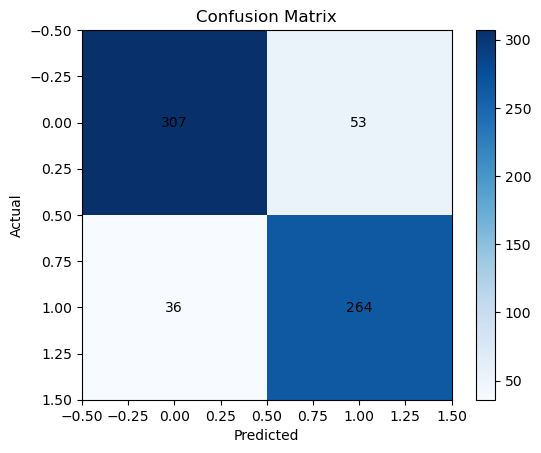

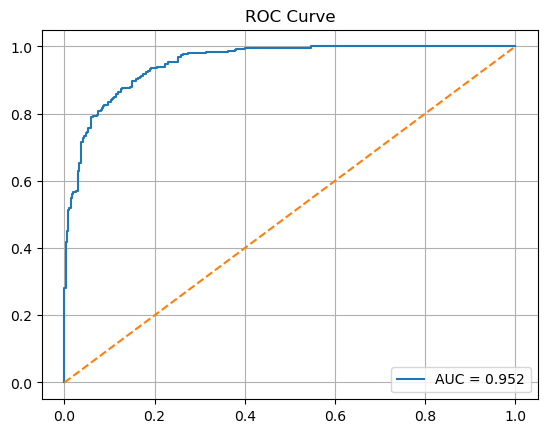

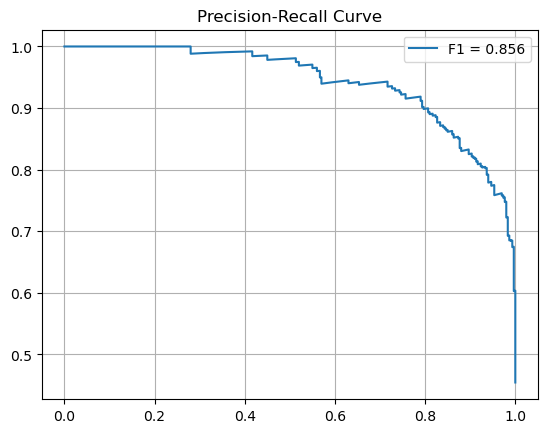

ROC-AUC Score: 0.952


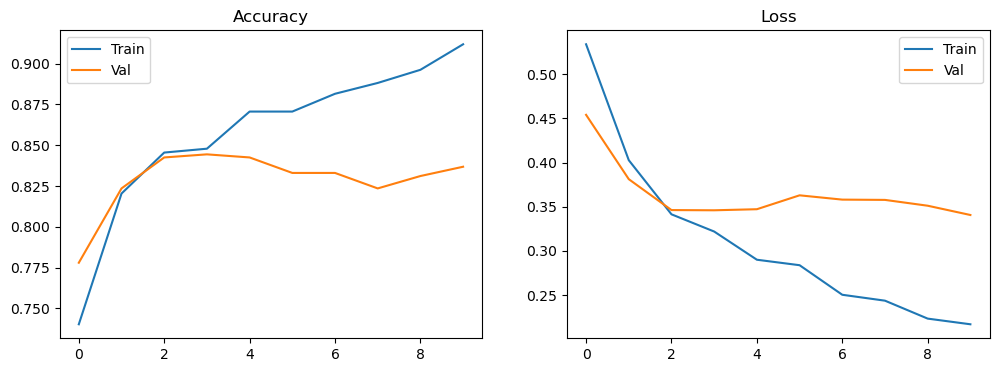

In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    f1_score,
    roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint

# =========================
# CONFIG
# =========================
img_size = 224
batch_size = 16
epochs = 10

train_dir = 'dataset Skin/train'
val_dir   = 'dataset Skin/val'
test_dir  = 'dataset Skin/test'

# =========================
# DATA
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary'
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary'
)

test_gen = val_datagen.flow_from_directory(
    test_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False
)

# =========================
# CLASS WEIGHTS
# =========================
classes = train_gen.classes
weights = compute_class_weight('balanced', classes=np.unique(classes), y=classes)
class_weights = dict(enumerate(weights))

# =========================
# MODEL (DenseNet121)
# =========================
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(img_size, img_size, 3)
)

# Freeze most layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# =========================
# CALLBACKS
# =========================
callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3),
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    ModelCheckpoint('densenet_model.keras', save_best_only=True)
]

# =========================
# TRAIN
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=epochs,
    class_weight=class_weights,
    callbacks=callbacks
)

# =========================
# EVALUATION
# =========================
loss, acc = model.evaluate(test_gen)
print(f"\nTest Accuracy: {acc*100:.2f}%")

y_pred = model.predict(test_gen).ravel()
y_pred_classes = (y_pred > 0.5).astype(int)
y_true = test_gen.classes

# =========================
# REPORT
# =========================
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred_classes))

# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred_classes)
print("Confusion Matrix:\n", cm)

plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

# =========================
# ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--')
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

# =========================
# PR CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_pred)
f1 = f1_score(y_true, y_pred_classes)

plt.plot(recall, precision, label=f'F1 = {f1:.3f}')
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

print(f"ROC-AUC Score: {roc_auc_score(y_true, y_pred):.3f}")

# =========================
# TRAINING CURVES
# =========================
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()

plt.show()

In [4]:
# =========================
# SAVE + METRICS FOR PAPER & GRAD-CAM
# =========================
import os
import time
import json
import pickle

# -------- SAVE MODEL --------
model.save("final_densenet_model.keras")
print("✅ Model saved")

# -------- SAVE CLASS LABELS --------
with open("class_indices.json", "w") as f:
    json.dump(train_gen.class_indices, f)

# -------- SAVE TRAINING HISTORY --------
with open("history.pkl", "wb") as f:
    pickle.dump(history.history, f)

# -------- MODEL SIZE --------
model_path = "final_densenet_model.keras"
size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"Model Size: {size_mb:.2f} MB")

# -------- TRAINING TIME --------
# (Only works if you defined start_time before training)
try:
    training_time = end_time - start_time
    print(f"Training Time: {training_time/60:.2f} minutes")
except:
    print("⚠️ Training time not recorded (wrap model.fit with time)")

# -------- INFERENCE TIME --------
# Take one batch
sample_batch = next(test_gen)[0]

# Warm-up
_ = model.predict(sample_batch, verbose=0)

# Measure
start_inf = time.time()
_ = model.predict(sample_batch, verbose=0)
end_inf = time.time()

time_per_image = ((end_inf - start_inf) / len(sample_batch)) * 1000
print(f"Inference Time: {time_per_image:.2f} ms/image")

# -------- OPTIONAL: AVERAGE INFERENCE --------
total_time = 0
total_images = 0

for i in range(len(test_gen)):
    images, _ = test_gen[i]

    start = time.time()
    _ = model.predict(images, verbose=0)
    end = time.time()

    total_time += (end - start)
    total_images += len(images)

avg_time = (total_time / total_images) * 1000
print(f"Average Inference Time: {avg_time:.2f} ms/image")

✅ Model saved
Model Size: 36.16 MB
⚠️ Training time not recorded (wrap model.fit with time)
Inference Time: 91.53 ms/image
Average Inference Time: 101.21 ms/image


Found 2110 images belonging to 2 classes.
Found 527 images belonging to 2 classes.
Found 660 images belonging to 2 classes.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 14,846,273 (56.63 MB)

Trainable params: 7,211,009 (27.51 MB)

Non-trainable params: 7,635,264 (29.13 MB)

Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


132/132 ━━━━━━━━━━━━━━━━━━━━ 812s 6s/step - accuracy: 0.7365 - loss: 0.5279 - val_accuracy: 0.8046 - val_loss: 0.4176 - learning_rate: 1.0000e-04
Epoch 2/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 802s 6s/step - accuracy: 0.8090 - loss: 0.3884 - val_accuracy: 0.8083 - val_loss: 0.4140 - learning_rate: 1.0000e-04
Epoch 3/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 805s 6s/step - accuracy: 0.8474 - loss: 0.3407 - val_accuracy: 0.8311 - val_loss: 0.3685 - learning_rate: 1.0000e-04
Epoch 4/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 824s 6s/step - accuracy: 0.8644 - loss: 0.3008 - val_accuracy: 0.8235 - val_loss: 0.4113 - learning_rate: 1.0000e-04
Epoch 5/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 809s 6s/step - accuracy: 0.8544 - loss: 0.2963 - val_accuracy: 0.8292 - val_loss: 0.3586 - learning_rate: 1.0000e-04
Epoch 6/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 817s 6s/step - accuracy: 0.8615 - loss: 0.2856 - val_accuracy: 0.8444 - val_loss: 0.3477 - learning_rate: 1.0000e-04
Epoch 7/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 808s 6s/step - accuracy: 0.86

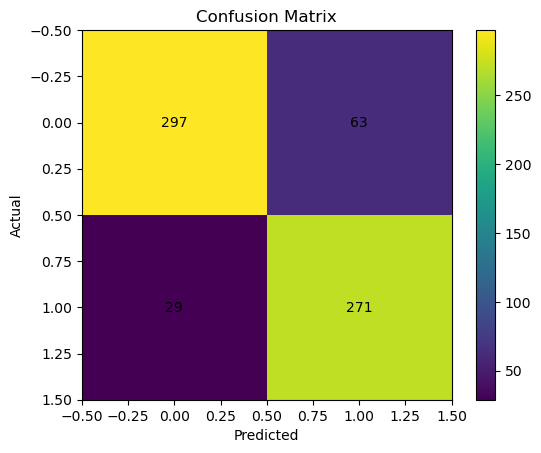

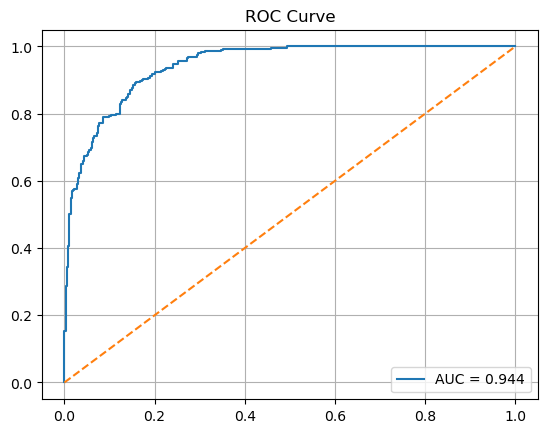

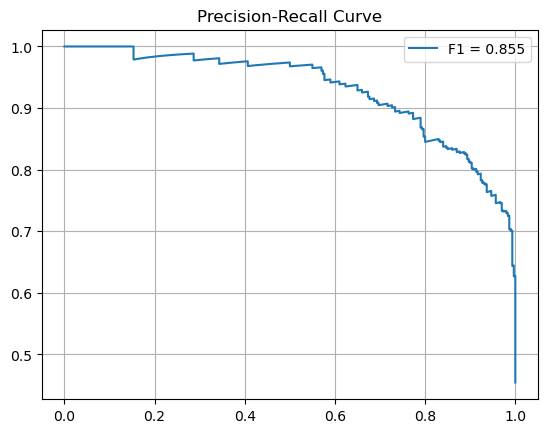

ROC-AUC Score: 0.944


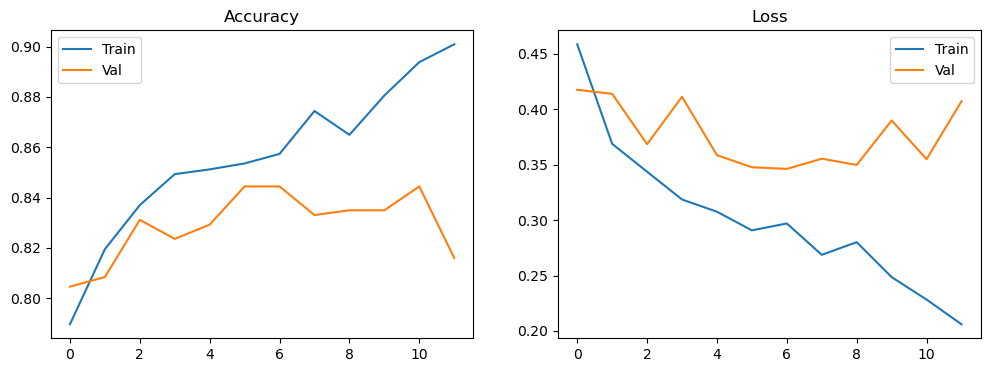

Model Size: 111.74 MB
42/42 ━━━━━━━━━━━━━━━━━━━━ 173s 4s/step
Inference Time: 172.865 sec


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    f1_score,
    roc_auc_score
)

# =========================
# CONFIG
# =========================
img_size = 224
batch_size = 16
epochs = 20

train_dir = 'dataset Skin/train'
val_dir   = 'dataset Skin/val'
test_dir  = 'dataset Skin/test'

# =========================
# DATA GENERATORS
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary'
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary'
)

test_gen = val_datagen.flow_from_directory(
    test_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False
)

# =========================
# CLASS WEIGHTS
# =========================
classes = train_gen.classes
weights = compute_class_weight('balanced', classes=np.unique(classes), y=classes)
class_weights = dict(enumerate(weights))

# =========================
# MODEL (VGG16)
# =========================
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(img_size, img_size, 3)
)

# Freeze most layers
for layer in base_model.layers[:-4]:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# =========================
# CALLBACKS
# =========================
callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3),
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('skin_cancer_vgg16.keras', save_best_only=True)
]

# =========================
# TRAIN
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=epochs,
    class_weight=class_weights,
    callbacks=callbacks
)

# =========================
# EVALUATION
# =========================
loss, acc = model.evaluate(test_gen)
print(f"\nTest Accuracy: {acc*100:.2f}%")

y_probs = model.predict(test_gen).ravel()
y_pred = (y_probs > 0.5).astype(int)
y_true = test_gen.classes

# =========================
# CLASSIFICATION REPORT
# =========================
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred))

# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred)

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

# =========================
# ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--')
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

# =========================
# PRECISION-RECALL CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_probs)
f1 = f1_score(y_true, y_pred)

plt.plot(recall, precision, label=f'F1 = {f1:.3f}')
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

print(f"ROC-AUC Score: {roc_auc_score(y_true, y_probs):.3f}")

# =========================
# TRAINING CURVES
# =========================
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()

plt.show()

# =========================
# SAVE MODEL + TIME
# =========================
model.save("skin_cancer_model.keras")

size_mb = os.path.getsize("skin_cancer_model.keras") / (1024*1024)
print("Model Size:", round(size_mb, 2), "MB")

start = time.time()
_ = model.predict(test_gen)
end = time.time()

print("Inference Time:", round(end-start, 3), "sec")

In [ ]:
model.save("skin_cancer_model.keras")


Found 2110 images belonging to 2 classes.
Found 527 images belonging to 2 classes.
Found 660 images belonging to 2 classes.


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_2    │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d_2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_3    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_3… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

Total params: 7,300,161 (27.85 MB)

Trainable params: 904,065 (3.45 MB)

Non-trainable params: 6,396,096 (24.40 MB)

Epoch 1/40


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


132/132 ━━━━━━━━━━━━━━━━━━━━ 291s 2s/step - accuracy: 0.6469 - loss: 0.6496 - val_accuracy: 0.7989 - val_loss: 0.4344 - learning_rate: 1.0000e-04
Epoch 2/40
132/132 ━━━━━━━━━━━━━━━━━━━━ 258s 2s/step - accuracy: 0.8021 - loss: 0.4364 - val_accuracy: 0.8197 - val_loss: 0.3872 - learning_rate: 1.0000e-04
Epoch 3/40
132/132 ━━━━━━━━━━━━━━━━━━━━ 258s 2s/step - accuracy: 0.8419 - loss: 0.3482 - val_accuracy: 0.8273 - val_loss: 0.3623 - learning_rate: 1.0000e-04
Epoch 4/40
132/132 ━━━━━━━━━━━━━━━━━━━━ 261s 2s/step - accuracy: 0.8439 - loss: 0.3318 - val_accuracy: 0.8330 - val_loss: 0.3564 - learning_rate: 1.0000e-04
Epoch 5/40
132/132 ━━━━━━━━━━━━━━━━━━━━ 252s 2s/step - accuracy: 0.8695 - loss: 0.2907 - val_accuracy: 0.8444 - val_loss: 0.3327 - learning_rate: 1.0000e-04
Epoch 6/40
132/132 ━━━━━━━━━━━━━━━━━━━━ 238s 2s/step - accuracy: 0.8735 - loss: 0.2751 - val_accuracy: 0.8539 - val_loss: 0.3509 - learning_rate: 1.0000e-04
Epoch 7/40
132/132 ━━━━━━━━━━━━━━━━━━━━ 237s 2s/step - accuracy: 0.89

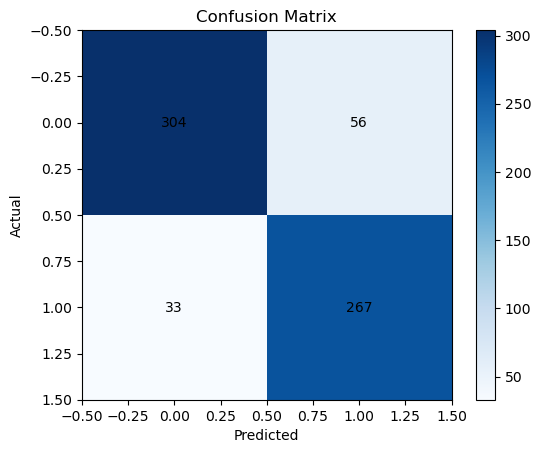

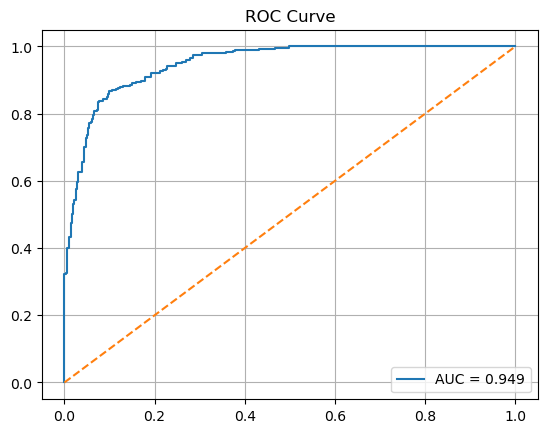

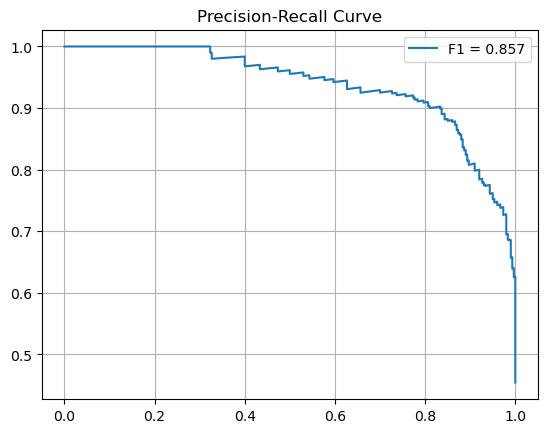

ROC-AUC Score: 0.949


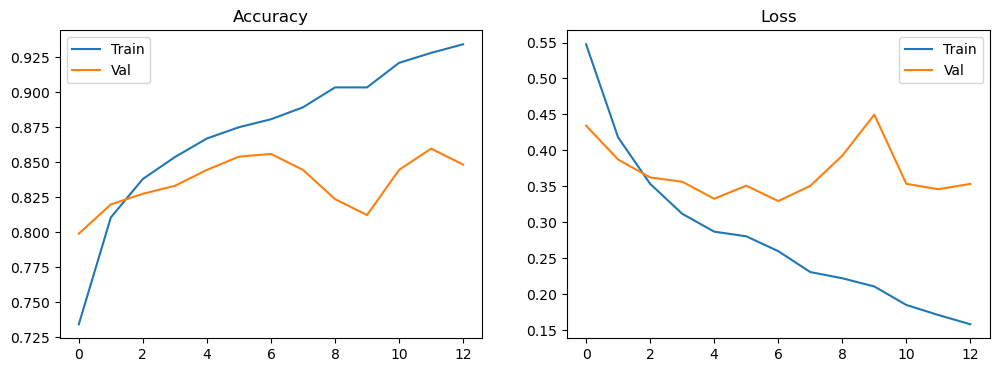

In [5]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    f1_score,
    roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint

# =========================
# CONFIG
# =========================
img_size = 224
batch_size = 16
epochs = 40

train_dir = 'dataset Skin/train'
val_dir   = 'dataset Skin/val'
test_dir  = 'dataset Skin/test'

# =========================
# DATA
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary'
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary'
)

test_gen = val_datagen.flow_from_directory(
    test_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False
)

# =========================
# CLASS WEIGHTS
# =========================
classes = train_gen.classes
weights = compute_class_weight('balanced', classes=np.unique(classes), y=classes)
class_weights = dict(enumerate(weights))

# =========================
# MODEL (DenseNet121)
# =========================
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(img_size, img_size, 3)
)

# Freeze most layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# =========================
# CALLBACKS
# =========================
callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3),
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    ModelCheckpoint('densenet_model.keras', save_best_only=True)
]

# =========================
# TRAIN
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=epochs,
    class_weight=class_weights,
    callbacks=callbacks
)

# =========================
# EVALUATION
# =========================
loss, acc = model.evaluate(test_gen)
print(f"\nTest Accuracy: {acc*100:.2f}%")

y_pred = model.predict(test_gen).ravel()
y_pred_classes = (y_pred > 0.5).astype(int)
y_true = test_gen.classes

# =========================
# REPORT
# =========================
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred_classes))

# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred_classes)
print("Confusion Matrix:\n", cm)

plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

# =========================
# ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--')
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

# =========================
# PR CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_pred)
f1 = f1_score(y_true, y_pred_classes)

plt.plot(recall, precision, label=f'F1 = {f1:.3f}')
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

print(f"ROC-AUC Score: {roc_auc_score(y_true, y_pred):.3f}")

# =========================
# TRAINING CURVES
# =========================
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()

plt.show()

Found 2110 images belonging to 2 classes.
Found 527 images belonging to 2 classes.
Found 660 images belonging to 2 classes.


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer_4[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

Total params: 7,300,161 (27.85 MB)

Trainable params: 904,065 (3.45 MB)

Non-trainable params: 6,396,096 (24.40 MB)

Epoch 1/50


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


132/132 ━━━━━━━━━━━━━━━━━━━━ 271s 2s/step - accuracy: 0.6420 - loss: 0.6680 - val_accuracy: 0.7628 - val_loss: 0.4758 - learning_rate: 1.0000e-04
Epoch 2/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 234s 2s/step - accuracy: 0.8369 - loss: 0.3647 - val_accuracy: 0.8349 - val_loss: 0.3935 - learning_rate: 1.0000e-04
Epoch 3/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 237s 2s/step - accuracy: 0.8379 - loss: 0.3460 - val_accuracy: 0.8482 - val_loss: 0.3545 - learning_rate: 1.0000e-04
Epoch 4/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 240s 2s/step - accuracy: 0.8436 - loss: 0.3281 - val_accuracy: 0.8577 - val_loss: 0.3523 - learning_rate: 1.0000e-04
Epoch 5/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 238s 2s/step - accuracy: 0.8585 - loss: 0.2901 - val_accuracy: 0.8235 - val_loss: 0.3718 - learning_rate: 1.0000e-04
Epoch 6/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.8788 - loss: 0.2606 - val_accuracy: 0.8254 - val_loss: 0.3654 - learning_rate: 1.0000e-04
Epoch 7/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.88

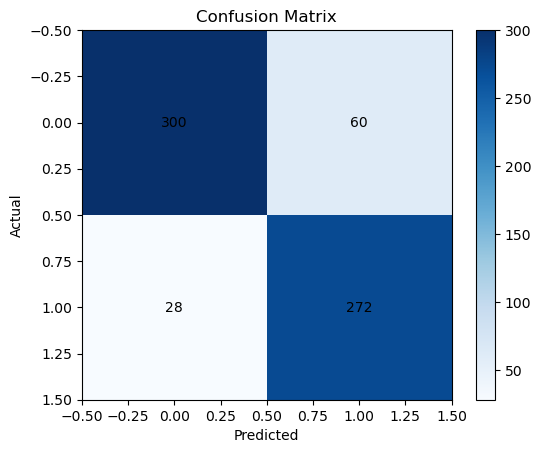

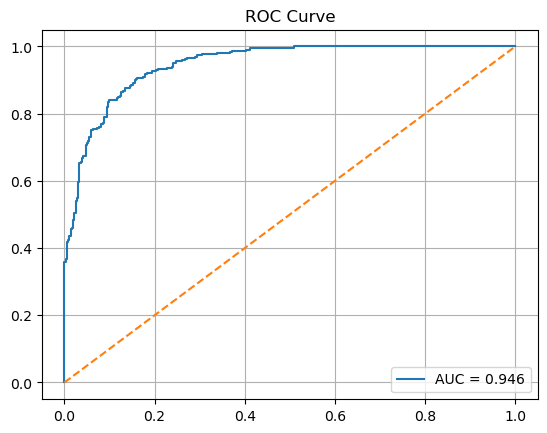

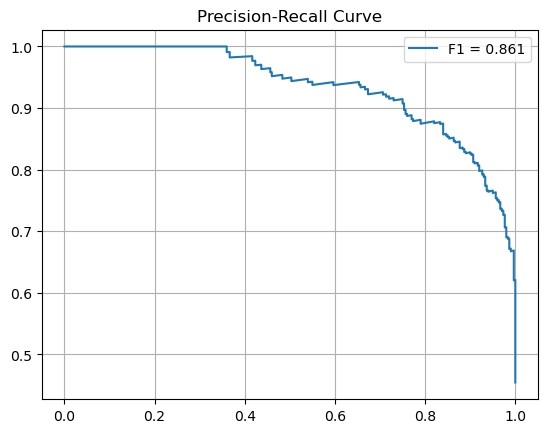

ROC-AUC Score: 0.946


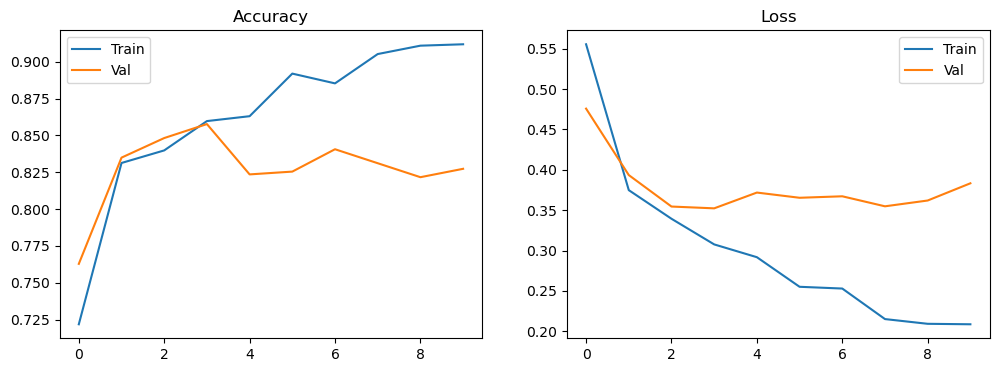

In [5]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    f1_score,
    roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint

# =========================
# CONFIG
# =========================
img_size = 224
batch_size = 16
epochs = 50

train_dir = 'dataset Skin/train'
val_dir   = 'dataset Skin/val'
test_dir  = 'dataset Skin/test'

# =========================
# DATA
# =========================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary'
)

val_gen = val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary'
)

test_gen = val_datagen.flow_from_directory(
    test_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False
)

# =========================
# CLASS WEIGHTS
# =========================
classes = train_gen.classes
weights = compute_class_weight('balanced', classes=np.unique(classes), y=classes)
class_weights = dict(enumerate(weights))

# =========================
# MODEL (DenseNet121)
# =========================
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(img_size, img_size, 3)
)

# Freeze most layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# =========================
# CALLBACKS
# =========================
callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3),
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    ModelCheckpoint('densenet_model.keras', save_best_only=True)
]

# =========================
# TRAIN
# =========================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=epochs,
    class_weight=class_weights,
    callbacks=callbacks
)

# =========================
# EVALUATION
# =========================
loss, acc = model.evaluate(test_gen)
print(f"\nTest Accuracy: {acc*100:.2f}%")

y_pred = model.predict(test_gen).ravel()
y_pred_classes = (y_pred > 0.5).astype(int)
y_true = test_gen.classes

# =========================
# REPORT
# =========================
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred_classes))

# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_true, y_pred_classes)
print("Confusion Matrix:\n", cm)

plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

# =========================
# ROC CURVE
# =========================
fpr, tpr, _ = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--')
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

# =========================
# PR CURVE
# =========================
precision, recall, _ = precision_recall_curve(y_true, y_pred)
f1 = f1_score(y_true, y_pred_classes)

plt.plot(recall, precision, label=f'F1 = {f1:.3f}')
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

print(f"ROC-AUC Score: {roc_auc_score(y_true, y_pred):.3f}")

# =========================
# TRAINING CURVES
# =========================
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()

plt.show()

Found 2110 images belonging to 2 classes.
Found 527 images belonging to 2 classes.
Found 660 images belonging to 2 classes.


C:\Users\usER\AppData\Local\Temp\ipykernel_10580\1898175524.py:75: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Epoch 1/50


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


66/66 ━━━━━━━━━━━━━━━━━━━━ 65s 823ms/step - accuracy: 0.5779 - loss: 0.7313 - val_accuracy: 0.7514 - val_loss: 0.5067 - learning_rate: 1.0000e-04
Epoch 2/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 54s 782ms/step - accuracy: 0.7356 - loss: 0.5251 - val_accuracy: 0.7533 - val_loss: 0.4826 - learning_rate: 1.0000e-04
Epoch 3/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 53s 762ms/step - accuracy: 0.7562 - loss: 0.4871 - val_accuracy: 0.7533 - val_loss: 0.4584 - learning_rate: 1.0000e-04
Epoch 4/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 53s 768ms/step - accuracy: 0.7978 - loss: 0.4701 - val_accuracy: 0.7704 - val_loss: 0.4634 - learning_rate: 1.0000e-04
Epoch 5/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 53s 755ms/step - accuracy: 0.8113 - loss: 0.4482 - val_accuracy: 0.8027 - val_loss: 0.4251 - learning_rate: 1.0000e-04
Epoch 6/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 54s 778ms/step - accuracy: 0.7948 - loss: 0.4213 - val_accuracy: 0.8083 - val_loss: 0.4352 - learning_rate: 1.0000e-04
Epoch 7/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 54s 783ms/step - accuracy: 0.82

Epoch 43/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 60s 877ms/step - accuracy: 0.8317 - loss: 0.3592 - val_accuracy: 0.8083 - val_loss: 0.4161 - learning_rate: 1.0000e-05
Epoch 44/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 52s 750ms/step - accuracy: 0.8473 - loss: 0.3433 - val_accuracy: 0.7951 - val_loss: 0.4128 - learning_rate: 1.0000e-05
Epoch 45/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 56s 810ms/step - accuracy: 0.8416 - loss: 0.3642 - val_accuracy: 0.8083 - val_loss: 0.4304 - learning_rate: 1.0000e-05
Epoch 46/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 52s 744ms/step - accuracy: 0.8355 - loss: 0.3766 - val_accuracy: 0.8027 - val_loss: 0.4246 - learning_rate: 1.0000e-05
Epoch 47/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 53s 764ms/step - accuracy: 0.8611 - loss: 0.3534 - val_accuracy: 0.7875 - val_loss: 0.4167 - learning_rate: 1.0000e-05
Epoch 48/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 51s 744ms/step - accuracy: 0.8129 - loss: 0.3873 - val_accuracy: 0.7723 - val_loss: 0.4442 - learning_rate: 1.0000e-05
Epoch 49/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 51s 738ms/ste

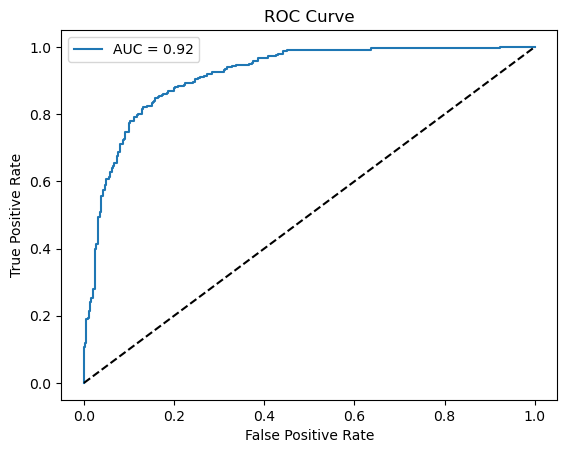

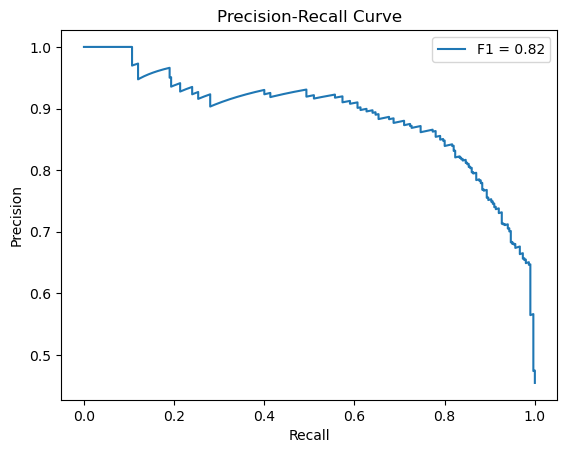

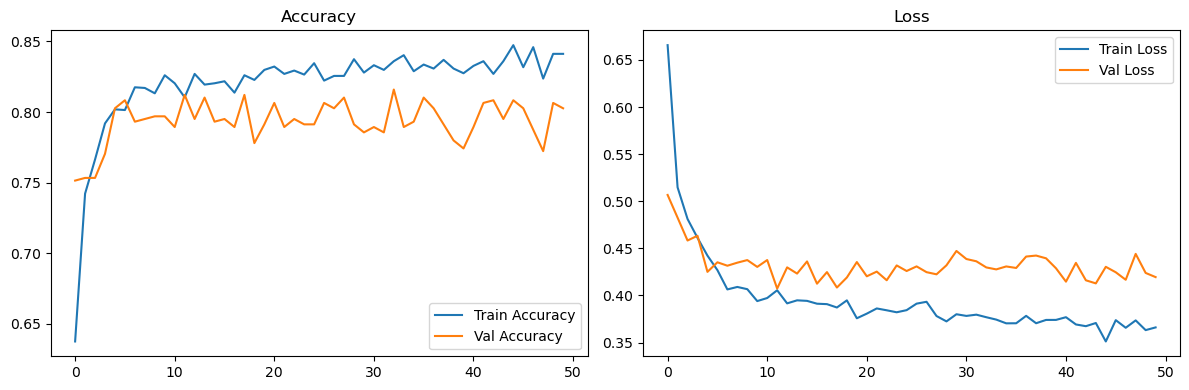

In [7]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    f1_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ReduceLROnPlateau

# =========================
# Step 1: Dataset Path
# =========================
dataset_path = 'dataset Skin'
train_dir = os.path.join(dataset_path, 'train')
val_dir = os.path.join(dataset_path, 'val')
test_dir = os.path.join(dataset_path, 'test')

# =========================
# Step 2: Parameters
# =========================
img_size = 150
batch_size = 32
epochs = 50

# =========================
# Step 3: Data Generator
# =========================
data_gen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=30,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

train_generator = data_gen.flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary'
)

val_generator = data_gen.flow_from_directory(
    val_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary'
)

test_generator = data_gen.flow_from_directory(
    test_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False
)

# =========================
# Step 4: MobileNetV2 Model
# =========================
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(img_size, img_size, 3)
)

base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# =========================
# Step 5: Training
# =========================
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.1,
    patience=3,
    verbose=1,
    min_lr=1e-5
)

history = model.fit(
    train_generator,
    epochs=epochs,
    validation_data=val_generator,
    callbacks=[reduce_lr]
)


# =========================
# Step 7: Evaluate Model
# =========================
loss, accuracy = model.evaluate(test_generator)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# =========================
# Step 8: Predictions
# =========================
y_pred = model.predict(test_generator)
y_pred_classes = (y_pred > 0.5).astype(int)
y_true = test_generator.classes

# =========================
# Step 9: Metrics
# =========================
print("Classification Report:\n", classification_report(y_true, y_pred_classes))
print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred_classes))

# ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_true, y_pred)
f1 = f1_score(y_true, y_pred_classes)

plt.figure()
plt.plot(recall, precision, label=f"F1 = {f1:.2f}")
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

# =========================
# Step 10: Training Curves
# =========================
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
model_vgg.save("skin_disease_mobilenetv2.h5")
print("Model saved as skin_disease_mobilenetv2.h5")

Model saved as skin_disease_mobilenetv2.h5


Found 2110 images belonging to 2 classes.
Found 527 images belonging to 2 classes.
Found 660 images belonging to 2 classes.
Epoch 1/10


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6503 - loss: 0.6210
Epoch 1: val_accuracy improved from -inf to 0.66414, saving model to best_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 394s 6s/step - accuracy: 0.6514 - loss: 0.6199 - val_accuracy: 0.6641 - val_loss: 0.6072 - learning_rate: 0.0010
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.7752 - loss: 0.4736
Epoch 2: val_accuracy improved from 0.66414 to 0.69829, saving model to best_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 393s 6s/step - accuracy: 0.7753 - loss: 0.4733 - val_accuracy: 0.6983 - val_loss: 0.5546 - learning_rate: 0.0010
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7904 - loss: 0.4390
Epoch 3: val_accuracy improved from 0.69829 to 0.74953, saving model to best_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 350s 5s/step - accuracy: 0.7904 - loss: 0.4389 - val_accuracy: 0.7495 - val_loss: 0.4859 - learning_rate: 0.0010
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8059 - loss: 0.

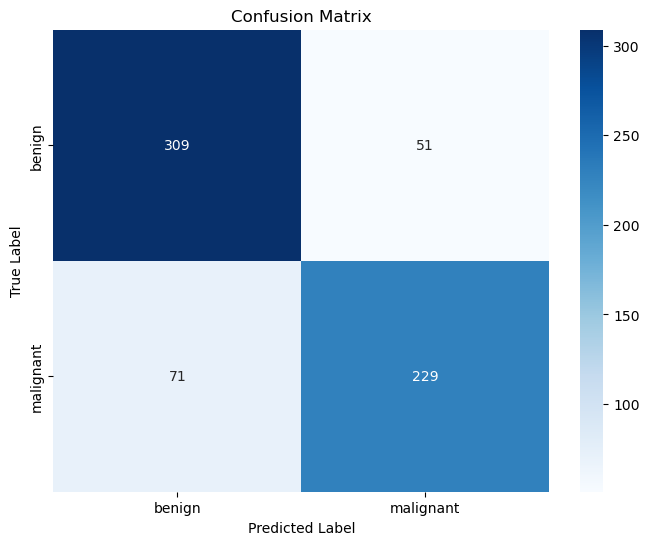

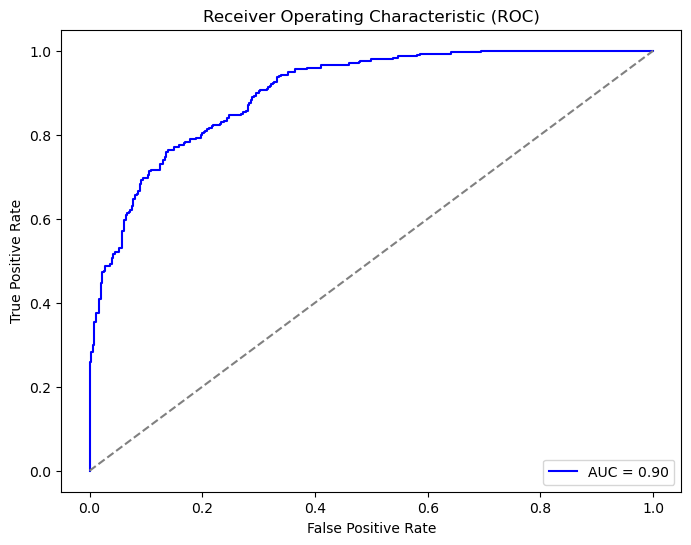

In [30]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import Xception
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns

# Paths
base_dir = 'dataset Skin'  # Adjust this if the dataset is in a different location
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Data generators
train_datagen = ImageDataGenerator(rescale=1.0/255, rotation_range=20, width_shift_range=0.2, height_shift_range=0.2, 
                                   zoom_range=0.2, horizontal_flip=True)
val_datagen = ImageDataGenerator(rescale=1.0/255)
test_datagen = ImageDataGenerator(rescale=1.0/255)

train_gen = train_datagen.flow_from_directory(train_dir, target_size=(224, 224), batch_size=32, class_mode='binary')
val_gen = val_datagen.flow_from_directory(val_dir, target_size=(224, 224), batch_size=32, class_mode='binary')
test_gen = test_datagen.flow_from_directory(test_dir, target_size=(224, 224), batch_size=32, class_mode='binary', shuffle=False)

# Model setup
base_model = Xception(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)  # Dropout for regularization
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(1, activation='sigmoid')(x)  # Binary classification

model = Model(inputs=base_model.input, outputs=predictions)

# Freeze initial layers
for layer in base_model.layers:
    layer.trainable = False

# Compile model
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Callbacks
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
early_stopping = EarlyStopping(monitor='val_loss', patience=5, verbose=1, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, verbose=1)

# Train model with fewer epochs (e.g., 10 or 15)
history = model.fit(train_gen, epochs=10, validation_data=val_gen, callbacks=[checkpoint, early_stopping, reduce_lr])

# Evaluate the model
model.load_weights('best_model.keras')  # Load the best model
test_loss, test_accuracy = model.evaluate(test_gen)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Predictions
y_pred_probs = model.predict(test_gen)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()
y_true = test_gen.classes

# Classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=list(test_gen.class_indices.keys())))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(test_gen.class_indices.keys()), yticklabels=list(test_gen.class_indices.keys()))
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.title('Receiver Operating Characteristic (ROC)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# If the results are good, you can increase the epochs and continue training, or fine-tune further if needed.


Found 2110 images belonging to 2 classes.
Found 527 images belonging to 2 classes.
Found 660 images belonging to 2 classes.
Epoch 1/20


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7001 - loss: 0.5829
Epoch 1: val_accuracy improved from -inf to 0.74763, saving model to best_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 311s 5s/step - accuracy: 0.7005 - loss: 0.5823 - val_accuracy: 0.7476 - val_loss: 0.5619 - learning_rate: 0.0010
Epoch 2/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7605 - loss: 0.4766
Epoch 2: val_accuracy did not improve from 0.74763
66/66 ━━━━━━━━━━━━━━━━━━━━ 360s 5s/step - accuracy: 0.7608 - loss: 0.4763 - val_accuracy: 0.6983 - val_loss: 0.5372 - learning_rate: 0.0010
Epoch 3/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7987 - loss: 0.4235
Epoch 3: val_accuracy did not improve from 0.74763
66/66 ━━━━━━━━━━━━━━━━━━━━ 361s 5s/step - accuracy: 0.7986 - loss: 0.4236 - val_accuracy: 0.7287 - val_loss: 0.5048 - learning_rate: 0.0010
Epoch 4/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7965 - loss: 0.4064
Epoch 4: val_accuracy improved from 0.74763 to 0.75712, saving model to

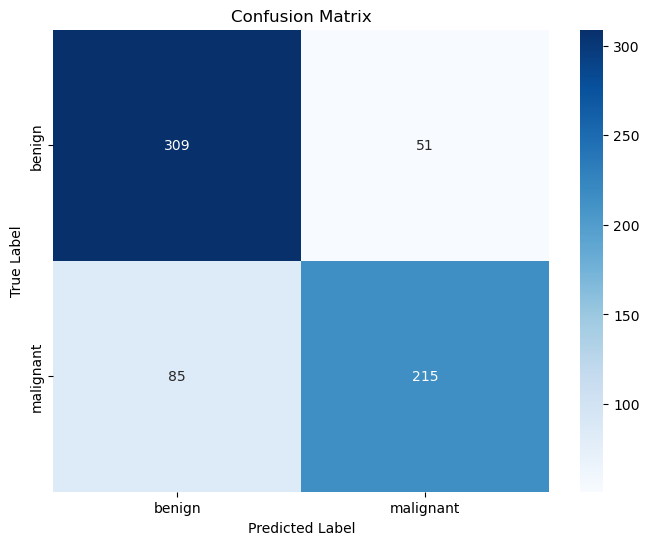

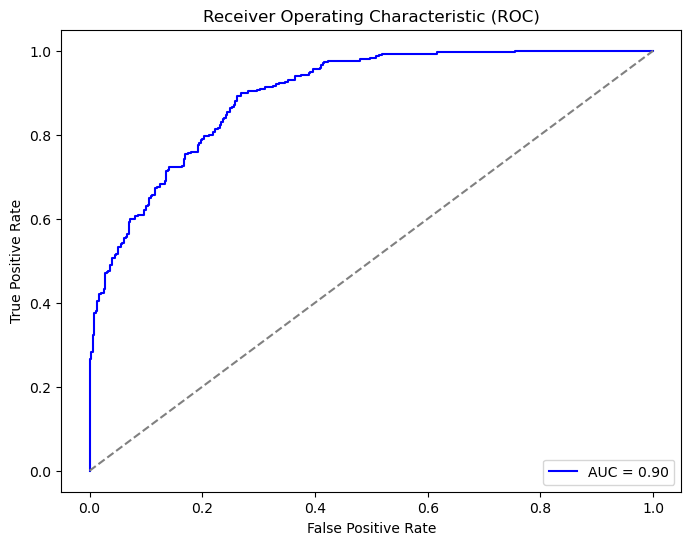

In [31]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import Xception
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns

# Paths
base_dir = 'dataset Skin'  # Adjust this if the dataset is in a different location
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Data generators
train_datagen = ImageDataGenerator(rescale=1.0/255, rotation_range=20, width_shift_range=0.2, height_shift_range=0.2, 
                                   zoom_range=0.2, horizontal_flip=True)
val_datagen = ImageDataGenerator(rescale=1.0/255)
test_datagen = ImageDataGenerator(rescale=1.0/255)

train_gen = train_datagen.flow_from_directory(train_dir, target_size=(224, 224), batch_size=32, class_mode='binary')
val_gen = val_datagen.flow_from_directory(val_dir, target_size=(224, 224), batch_size=32, class_mode='binary')
test_gen = test_datagen.flow_from_directory(test_dir, target_size=(224, 224), batch_size=32, class_mode='binary', shuffle=False)

# Model setup
base_model = Xception(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)  # Dropout for regularization
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(1, activation='sigmoid')(x)  # Binary classification

model = Model(inputs=base_model.input, outputs=predictions)

# Freeze initial layers
for layer in base_model.layers:
    layer.trainable = False

# Compile model
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Callbacks
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
early_stopping = EarlyStopping(monitor='val_loss', patience=5, verbose=1, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, verbose=1)

# Train model with fewer epochs (e.g., 10 or 15)
history = model.fit(train_gen, epochs=20, validation_data=val_gen, callbacks=[checkpoint, early_stopping, reduce_lr])

# Evaluate the model
model.load_weights('best_model.keras')  # Load the best model
test_loss, test_accuracy = model.evaluate(test_gen)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Predictions
y_pred_probs = model.predict(test_gen)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()
y_true = test_gen.classes

# Classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=list(test_gen.class_indices.keys())))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(test_gen.class_indices.keys()), yticklabels=list(test_gen.class_indices.keys()))
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.title('Receiver Operating Characteristic (ROC)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# If the results are good, you can increase the epochs and continue training, or fine-tune further if needed.


INCEPTIONV3 SKIN CANCER CLASSIFICATION

TensorFlow version: 2.17.0

CHECKING DATASET

Base path:
C:\Users\usER\dataset Skin

Train path:
C:\Users\usER\dataset Skin\train

Validation path:
C:\Users\usER\dataset Skin\val

Test path:
C:\Users\usER\dataset Skin\test

✓ Dataset structure verified successfully!

DATASET STATISTICS

Training:
   BENIGN: 1152
   MALIGNANT: 958
   Total: 2110

Validation:
   BENIGN: 288
   MALIGNANT: 239
   Total: 527

Testing:
   BENIGN: 360
   MALIGNANT: 300
   Total: 660

CREATING IMAGE GENERATORS
Found 2110 images belonging to 2 classes.
Found 527 images belonging to 2 classes.
Found 660 images belonging to 2 classes.

Class indices:
{'BENIGN': 0, 'MALIGNANT': 1}

Training images: 2110
Validation images: 527
Testing images: 660

BUILDING INCEPTIONV3 MODEL

Total base model layers: 311
Trainable base model layers: 30
Frozen base model layers: 281

Model compiled successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 22,360,353 (85.30 MB)

Trainable params: 5,713,601 (21.80 MB)

Non-trainable params: 16,646,752 (63.50 MB)


STARTING TRAINING
Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 465s 7s/step - accuracy: 0.6636 - loss: 0.5883 - val_accuracy: 0.7571 - val_loss: 0.5012
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 445s 7s/step - accuracy: 0.8258 - loss: 0.3729 - val_accuracy: 0.8197 - val_loss: 0.3854
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 431s 6s/step - accuracy: 0.8657 - loss: 0.3142 - val_accuracy: 0.8406 - val_loss: 0.3747
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 408s 6s/step - accuracy: 0.8792 - loss: 0.2730 - val_accuracy: 0.8311 - val_loss: 0.4146
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 454s 7s/step - accuracy: 0.9132 - loss: 0.2149 - val_accuracy: 0.8406 - val_loss: 0.4077
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 473s 7s/step - accuracy: 0.9004 - loss: 0.2256 - val_accuracy: 0.8140 - val_loss: 0.4375
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 415s 6s/step - accuracy: 0.9200 - loss: 0.2069 - val_accuracy: 0.8046 - val_loss: 0.4606
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 390s 6s/step - accuracy: 0.9326 - loss: 0.1642 - val_a


TRAINING COMPLETED

Total training time: 70.08 minutes

Model saved successfully:
C:\Users\usER\inceptionv3_skin_cancer_model.h5

TRAINING CURVES


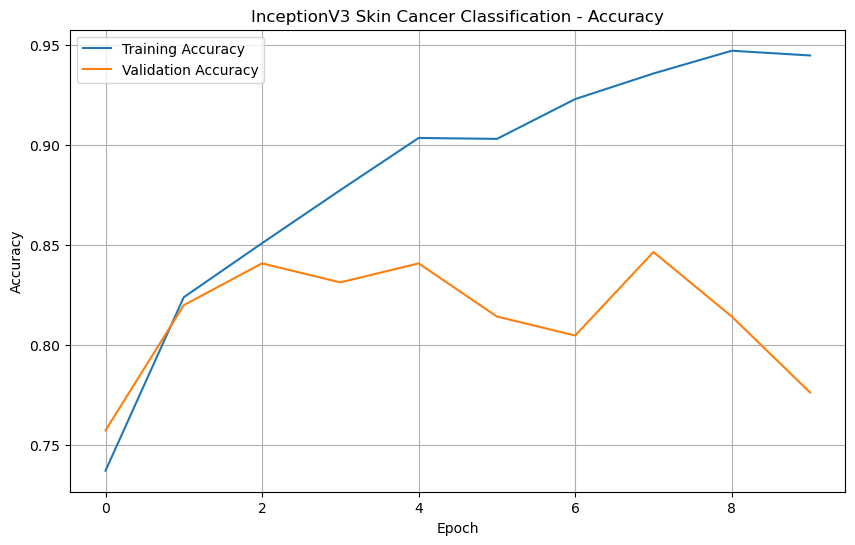

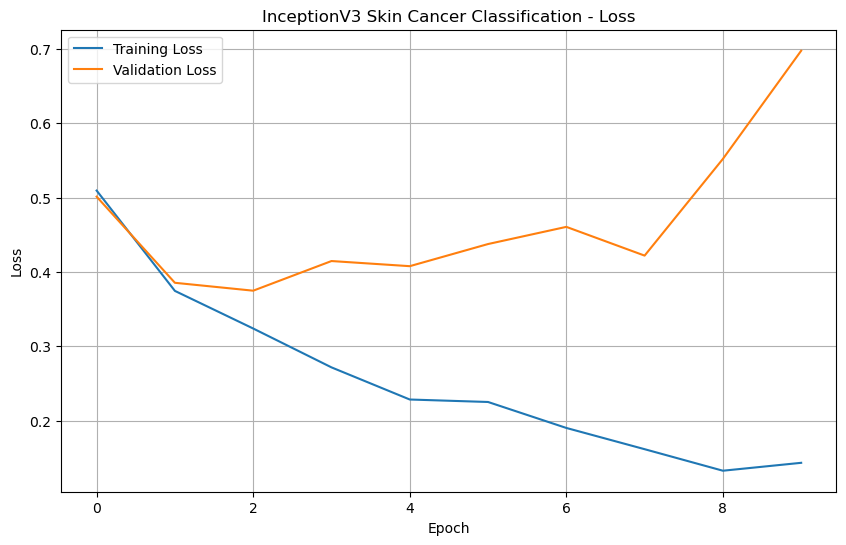


Final Training Accuracy: 94.45%
Final Validation Accuracy: 77.61%
Final Training Loss: 0.1432
Final Validation Loss: 0.6975

TESTING MODEL
21/21 ━━━━━━━━━━━━━━━━━━━━ 80s 4s/step - accuracy: 0.8937 - loss: 0.3151

Test Loss: 0.5549
Test Accuracy: 81.82%

GENERATING PREDICTIONS
21/21 ━━━━━━━━━━━━━━━━━━━━ 90s 4s/step

Total inference time: 90.3751 seconds
Average inference time per image: 0.136932 seconds
Images processed: 660

CONFUSION MATRIX
[[339  21]
 [ 99 201]]


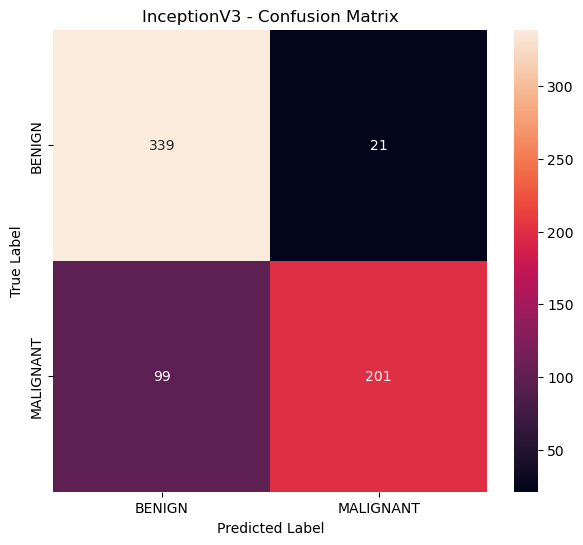


True Negative (TN): 339
False Positive (FP): 21
False Negative (FN): 99
True Positive (TP): 201

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      BENIGN     0.7740    0.9417    0.8496       360
   MALIGNANT     0.9054    0.6700    0.7701       300

    accuracy                         0.8182       660
   macro avg     0.8397    0.8058    0.8099       660
weighted avg     0.8337    0.8182    0.8135       660


ROC-AUC
ROC-AUC: 0.9217
ROC-AUC (%): 92.17%


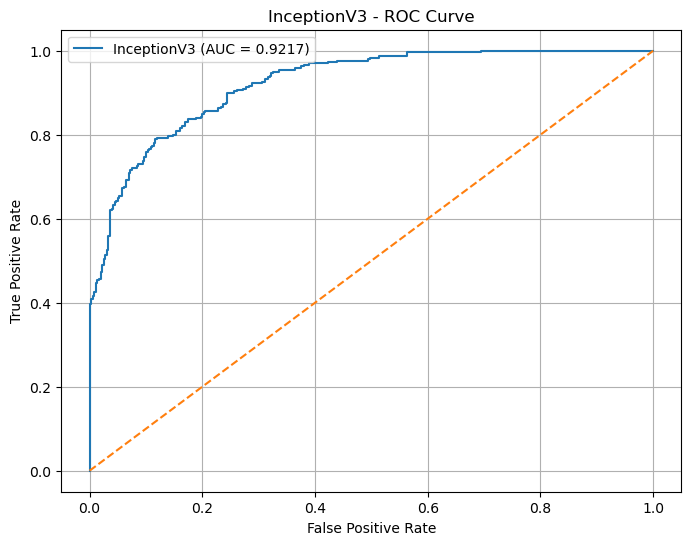


PRECISION-RECALL ANALYSIS
Average Precision (AP): 0.9135
Average Precision (%): 91.35%


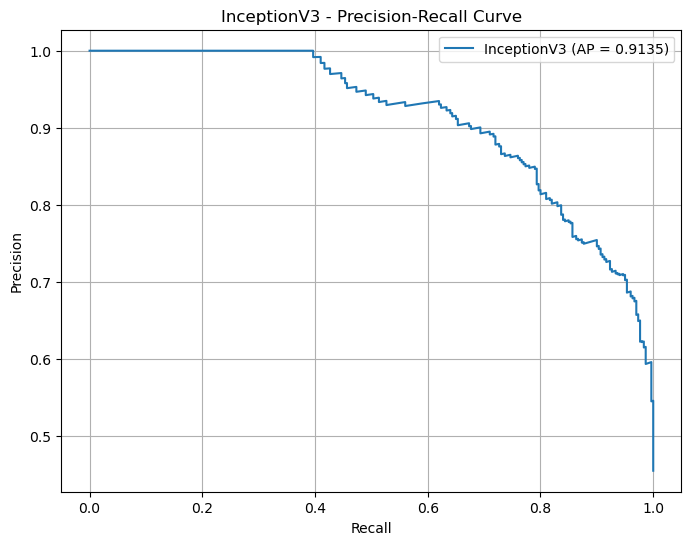


SENSITIVITY AND SPECIFICITY
Sensitivity: 0.6700
Sensitivity (%): 67.00%
Specificity: 0.9417
Specificity (%): 94.17%

MODEL SIZE
Model size: 129.51 MB


FINAL INCEPTIONV3 RESULTS
Training Accuracy       : 94.45%
Validation Accuracy     : 77.61%
Test Accuracy           : 81.82%
ROC-AUC                 : 92.17%
Average Precision       : 91.35%
Sensitivity             : 67.00%
Specificity             : 94.17%
Training Time           : 70.08 minutes
Avg. Inference/Image    : 0.136932 seconds
Model Size              : 129.51 MB
Model File              : inceptionv3_skin_cancer_model.h5
EXPERIMENT COMPLETED SUCCESSFULLY


In [2]:
# ============================================================
# INCEPTIONV3 FOR SKIN CANCER CLASSIFICATION
# 10 EPOCHS - H5 MODEL
# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.inception_v3 import (
    InceptionV3,
    preprocess_input
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# Suppress non-critical warnings
warnings.filterwarnings("ignore")

print("=" * 70)
print("INCEPTIONV3 SKIN CANCER CLASSIFICATION")
print("=" * 70)

print("\nTensorFlow version:", tf.__version__)


# ============================================================
# 2. DATASET PATH
# ============================================================

base_path = r"dataset Skin"

train_path = os.path.join(base_path, "train")
val_path = os.path.join(base_path, "val")
test_path = os.path.join(base_path, "test")

categories = ['BENIGN', 'MALIGNANT']

IMG_SIZE = (299, 299)
BATCH_SIZE = 32


# ============================================================
# 3. CHECK DATASET STRUCTURE
# ============================================================

print("\n" + "=" * 70)
print("CHECKING DATASET")
print("=" * 70)

print("\nBase path:")
print(os.path.abspath(base_path))

print("\nTrain path:")
print(os.path.abspath(train_path))

print("\nValidation path:")
print(os.path.abspath(val_path))

print("\nTest path:")
print(os.path.abspath(test_path))


if not os.path.exists(base_path):
    raise FileNotFoundError(
        f"\nDataset folder not found:\n{os.path.abspath(base_path)}"
        "\n\nPlease make sure the 'dataset Skin' folder is in the "
        "same directory as your Jupyter Notebook."
    )

if not os.path.exists(train_path):
    raise FileNotFoundError(
        f"\nTraining folder not found:\n{os.path.abspath(train_path)}"
    )

if not os.path.exists(val_path):
    raise FileNotFoundError(
        f"\nValidation folder not found:\n{os.path.abspath(val_path)}"
    )

if not os.path.exists(test_path):
    raise FileNotFoundError(
        f"\nTesting folder not found:\n{os.path.abspath(test_path)}"
    )


for category in categories:

    train_folder = os.path.join(train_path, category)
    val_folder = os.path.join(val_path, category)
    test_folder = os.path.join(test_path, category)

    if not os.path.exists(train_folder):
        raise FileNotFoundError(
            f"Training class folder not found:\n{train_folder}"
        )

    if not os.path.exists(val_folder):
        raise FileNotFoundError(
            f"Validation class folder not found:\n{val_folder}"
        )

    if not os.path.exists(test_folder):
        raise FileNotFoundError(
            f"Testing class folder not found:\n{test_folder}"
        )

print("\n✓ Dataset structure verified successfully!")


# ============================================================
# 4. COUNT IMAGES
# ============================================================

def count_images(folder):

    extensions = (
        '.jpg',
        '.jpeg',
        '.png',
        '.bmp',
        '.tif',
        '.tiff'
    )

    count = 0

    for root, dirs, files in os.walk(folder):

        for file in files:

            if file.lower().endswith(extensions):
                count += 1

    return count


print("\n" + "=" * 70)
print("DATASET STATISTICS")
print("=" * 70)

dataset_counts = {}

for split_name, split_path in [
    ("Training", train_path),
    ("Validation", val_path),
    ("Testing", test_path)
]:

    dataset_counts[split_name] = {}

    print(f"\n{split_name}:")

    total = 0

    for category in categories:

        folder = os.path.join(split_path, category)

        count = count_images(folder)

        dataset_counts[split_name][category] = count

        print(f"   {category}: {count}")

        total += count

    dataset_counts[split_name]["Total"] = total

    print(f"   Total: {total}")


# ============================================================
# 5. DATA AUGMENTATION
# ============================================================

print("\n" + "=" * 70)
print("CREATING IMAGE GENERATORS")
print("=" * 70)

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)


# ============================================================
# 6. TRAINING GENERATOR
# ============================================================

train_gen = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=categories,
    shuffle=True
)


# ============================================================
# 7. VALIDATION GENERATOR
# ============================================================

val_gen = val_datagen.flow_from_directory(
    val_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=categories,
    shuffle=False
)


# ============================================================
# 8. TEST GENERATOR
# ============================================================

test_gen = test_datagen.flow_from_directory(
    test_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=categories,
    shuffle=False
)


print("\nClass indices:")
print(train_gen.class_indices)

print("\nTraining images:", train_gen.samples)
print("Validation images:", val_gen.samples)
print("Testing images:", test_gen.samples)


# ============================================================
# 9. BUILD INCEPTIONV3 BASE MODEL
# ============================================================

print("\n" + "=" * 70)
print("BUILDING INCEPTIONV3 MODEL")
print("=" * 70)

base_model = InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(299, 299, 3)
)


# Freeze all layers
for layer in base_model.layers:
    layer.trainable = False


# Unfreeze last 30 layers
for layer in base_model.layers[-30:]:
    layer.trainable = True


trainable_layers = sum(
    1 for layer in base_model.layers
    if layer.trainable
)

total_layers = len(base_model.layers)

print("\nTotal base model layers:", total_layers)
print("Trainable base model layers:", trainable_layers)
print("Frozen base model layers:", total_layers - trainable_layers)


# ============================================================
# 10. BUILD CLASSIFICATION MODEL
# ============================================================

model = Sequential([

    base_model,

    GlobalAveragePooling2D(),

    Dense(
        256,
        activation='relu'
    ),

    Dropout(0.5),

    Dense(
        128,
        activation='relu'
    ),

    Dropout(0.3),

    Dense(
        1,
        activation='sigmoid'
    )
])


# ============================================================
# 11. COMPILE MODEL
# ============================================================

model.compile(
    optimizer=Adam(
        learning_rate=1e-4
    ),

    loss='binary_crossentropy',

    metrics=[
        'accuracy'
    ]
)


print("\nModel compiled successfully!")


# ============================================================
# 12. MODEL SUMMARY
# ============================================================

model.summary()


# ============================================================
# 13. TRAIN MODEL - 10 EPOCHS
# ============================================================

print("\n" + "=" * 70)
print("STARTING TRAINING")
print("=" * 70)

start_training_time = time.time()

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    verbose=1
)

end_training_time = time.time()

training_time = end_training_time - start_training_time

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print(
    f"\nTotal training time: "
    f"{training_time / 60:.2f} minutes"
)


# ============================================================
# 14. SAVE MODEL AS H5
# ============================================================

model_filename = "inceptionv3_skin_cancer_model.h5"

model.save(model_filename)

print("\nModel saved successfully:")
print(os.path.abspath(model_filename))


# ============================================================
# 15. TRAINING CURVES
# ============================================================

print("\n" + "=" * 70)
print("TRAINING CURVES")
print("=" * 70)

plt.figure(figsize=(10, 6))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title(
    'InceptionV3 Skin Cancer Classification - Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(10, 6))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title(
    'InceptionV3 Skin Cancer Classification - Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 16. FINAL TRAINING RESULTS
# ============================================================

final_train_accuracy = history.history['accuracy'][-1]
final_val_accuracy = history.history['val_accuracy'][-1]

final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]

print("\nFinal Training Accuracy:",
      f"{final_train_accuracy * 100:.2f}%")

print("Final Validation Accuracy:",
      f"{final_val_accuracy * 100:.2f}%")

print("Final Training Loss:",
      f"{final_train_loss:.4f}")

print("Final Validation Loss:",
      f"{final_val_loss:.4f}")


# ============================================================
# 17. TEST MODEL
# ============================================================

print("\n" + "=" * 70)
print("TESTING MODEL")
print("=" * 70)

test_loss, test_accuracy = model.evaluate(
    test_gen,
    verbose=1
)

print("\nTest Loss:",
      f"{test_loss:.4f}")

print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)


# ============================================================
# 18. GENERATE PREDICTIONS
# ============================================================

print("\n" + "=" * 70)
print("GENERATING PREDICTIONS")
print("=" * 70)

# Make sure generator starts from the beginning
test_gen.reset()

prediction_start_time = time.time()

y_probs = model.predict(
    test_gen,
    verbose=1
)

prediction_end_time = time.time()

y_probs = y_probs.ravel()

# Binary predictions
y_pred = (
    y_probs >= 0.5
).astype(int)

# True labels
y_true = test_gen.classes


# ============================================================
# 19. INFERENCE TIME
# ============================================================

total_inference_time = (
    prediction_end_time -
    prediction_start_time
)

num_test_images = len(y_true)

average_inference_time = (
    total_inference_time /
    num_test_images
)

print(
    "\nTotal inference time:",
    f"{total_inference_time:.4f} seconds"
)

print(
    "Average inference time per image:",
    f"{average_inference_time:.6f} seconds"
)

print(
    "Images processed:",
    num_test_images
)


# ============================================================
# 20. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(cm)


plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=categories,
    yticklabels=categories
)

plt.title(
    'InceptionV3 - Confusion Matrix'
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()


# ============================================================
# 21. EXTRACT TP, TN, FP, FN
# ============================================================

if cm.shape == (2, 2):

    tn, fp, fn, tp = cm.ravel()

else:

    tn = fp = fn = tp = 0


print("\nTrue Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)


# ============================================================
# 22. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

report = classification_report(
    y_true,
    y_pred,
    target_names=categories,
    digits=4
)

print(report)


# ============================================================
# 23. ROC CURVE AND ROC-AUC
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_probs
)

roc_auc = auc(
    fpr,
    tpr
)


print("\n" + "=" * 70)
print("ROC-AUC")
print("=" * 70)

print(
    "ROC-AUC:",
    f"{roc_auc:.4f}"
)

print(
    "ROC-AUC (%):",
    f"{roc_auc * 100:.2f}%"
)


plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'InceptionV3 (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title(
    'InceptionV3 - ROC Curve'
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 24. PRECISION-RECALL CURVE
# ============================================================

precision, recall, pr_thresholds = precision_recall_curve(
    y_true,
    y_probs
)

average_precision = average_precision_score(
    y_true,
    y_probs
)


print("\n" + "=" * 70)
print("PRECISION-RECALL ANALYSIS")
print("=" * 70)

print(
    "Average Precision (AP):",
    f"{average_precision:.4f}"
)

print(
    "Average Precision (%):",
    f"{average_precision * 100:.2f}%"
)


plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f'InceptionV3 (AP = {average_precision:.4f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')

plt.title(
    'InceptionV3 - Precision-Recall Curve'
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 25. SENSITIVITY AND SPECIFICITY
# ============================================================

if (tp + fn) > 0:

    sensitivity = tp / (tp + fn)

else:

    sensitivity = 0


if (tn + fp) > 0:

    specificity = tn / (tn + fp)

else:

    specificity = 0


print("\n" + "=" * 70)
print("SENSITIVITY AND SPECIFICITY")
print("=" * 70)

print(
    "Sensitivity:",
    f"{sensitivity:.4f}"
)

print(
    "Sensitivity (%):",
    f"{sensitivity * 100:.2f}%"
)

print(
    "Specificity:",
    f"{specificity:.4f}"
)

print(
    "Specificity (%):",
    f"{specificity * 100:.2f}%"
)


# ============================================================
# 26. MODEL SIZE
# ============================================================

model_size_bytes = os.path.getsize(
    model_filename
)

model_size_mb = (
    model_size_bytes /
    (1024 ** 2)
)


print("\n" + "=" * 70)
print("MODEL SIZE")
print("=" * 70)

print(
    "Model size:",
    f"{model_size_mb:.2f} MB"
)


# ============================================================
# 27. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("FINAL INCEPTIONV3 RESULTS")
print("=" * 70)

print(
    f"Training Accuracy       : "
    f"{final_train_accuracy * 100:.2f}%"
)

print(
    f"Validation Accuracy     : "
    f"{final_val_accuracy * 100:.2f}%"
)

print(
    f"Test Accuracy           : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"ROC-AUC                 : "
    f"{roc_auc * 100:.2f}%"
)

print(
    f"Average Precision       : "
    f"{average_precision * 100:.2f}%"
)

print(
    f"Sensitivity             : "
    f"{sensitivity * 100:.2f}%"
)

print(
    f"Specificity             : "
    f"{specificity * 100:.2f}%"
)

print(
    f"Training Time           : "
    f"{training_time / 60:.2f} minutes"
)

print(
    f"Avg. Inference/Image    : "
    f"{average_inference_time:.6f} seconds"
)

print(
    f"Model Size              : "
    f"{model_size_mb:.2f} MB"
)

print(
    f"Model File              : "
    f"{model_filename}"
)

print("=" * 70)
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 70)